# HW2: Support Vector Machines

Machine Learning & Neural Networks for Neuroscience

Gebreab Tewelday  
Abraham Alemayehu Gebrelibanos

[GitHub repository](https://github.com/gebreabgithub/python-for-machine-learning)

Proposed division of work: Gebreab Tewelday - dataset simulation, perceptron and linear SVM comparison, and kernel comparison (Questions 1-3). Abraham Alemayehu Gebrelibanos - augmentation, label noise, higher-dimensional analysis, and the bonus (Questions 4-6 and bonus). Shared work - checking results, interpreting figures, and reviewing the report.

## Setup

We used a fixed seed of 42 for the datasets and separate fixed seeds for the noise experiments. We kept the test labels unchanged and fitted scaling on the training data only.

In [1]:
from io import BytesIO
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image as NotebookImage
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Perceptron
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix

SEED, N, REPEATS, K = 42, 4000, 5, 10000
plt.rcParams.update({
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'DejaVu Serif'],
    'font.size': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
})
COLORS = ['#2369a0', '#da7535']

def show_figure():
    """Display the plot inside the notebook."""
    plt.tight_layout()
    image_buffer = BytesIO()
    plt.savefig(image_buffer, format='png', dpi=170)
    display(NotebookImage(data=image_buffer.getvalue()))
    plt.close()

def scatter(ax, x, y, title):
    for label in (0, 1):
        ax.scatter(*x[y == label].T, s=7, alpha=.4, color=COLORS[label], label=f'Class {label}')
    ax.set(xlabel='X1', ylabel='X2', title=title)
    ax.set_aspect('equal', adjustable='box')


In [2]:
def svm(kernel, **kwargs):
    return make_pipeline(StandardScaler(), SVC(kernel=kernel, cache_size=512, **kwargs))

def metrics(model, x, y):
    pred = model.predict(x)
    return dict(accuracy=accuracy_score(y, pred), f1=f1_score(y, pred, zero_division=0),
                auc=roc_auc_score(y, model.decision_function(x)), confusion=confusion_matrix(y, pred).tolist())

def boundary(ax, model, x, y, title):
    lo, hi = x.min(axis=0) - .4, x.max(axis=0) + .4
    xx, yy = np.meshgrid(np.linspace(lo[0], hi[0], 160), np.linspace(lo[1], hi[1], 160))
    score = model.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, score > 0, levels=[-.5, .5, 1.5], colors=COLORS, alpha=.13)
    if score.min() < 0 < score.max(): ax.contour(xx, yy, score, levels=[0], colors='black', linewidths=1)
    scatter(ax, x, y, title)


def show_table(headers, rows):
    """Display a small Markdown table without requiring pandas."""
    lines = ['| ' + ' | '.join(headers) + ' |',
             '| ' + ' | '.join(['---'] * len(headers)) + ' |']
    lines.extend('| ' + ' | '.join(map(str, row)) + ' |' for row in rows)
    display(Markdown('\n'.join(lines)))

def percent(value):
    return f'{100 * value:.2f}%'


## 1. Dataset simulation

We generated 4,000 observations per dataset, with 2,000 observations in each class. Each observation has two coordinates, X1 and X2, and a label Y in {0, 1}. We used a stratified 70/30 split: 2,800 training observations and 1,200 test observations. Stratification preserves the equal class proportions.

For the linear dataset, we sampled two disks of radius 0.8, centered at (-2, -2) and (2, 2). Their centers are about 5.66 units apart, so the disks cannot overlap. We sampled angles uniformly and used radius = 0.8 sqrt(U), where U is uniform on [0, 1]. The square root gives uniform sampling over the disk area.

For the circular dataset, class 0 occupies a disk with radius at most 0.8. Class 1 occupies an annulus, a ring with inner radius 1.2 and outer radius 2.0. Its radius is sqrt(1.2^2 + (2.0^2 - 1.2^2)U). We interpret the assignment's circular "overlap" as one class surrounding the other, as shown in its example. The coordinate ranges overlap, but the clean class regions have a radial gap.


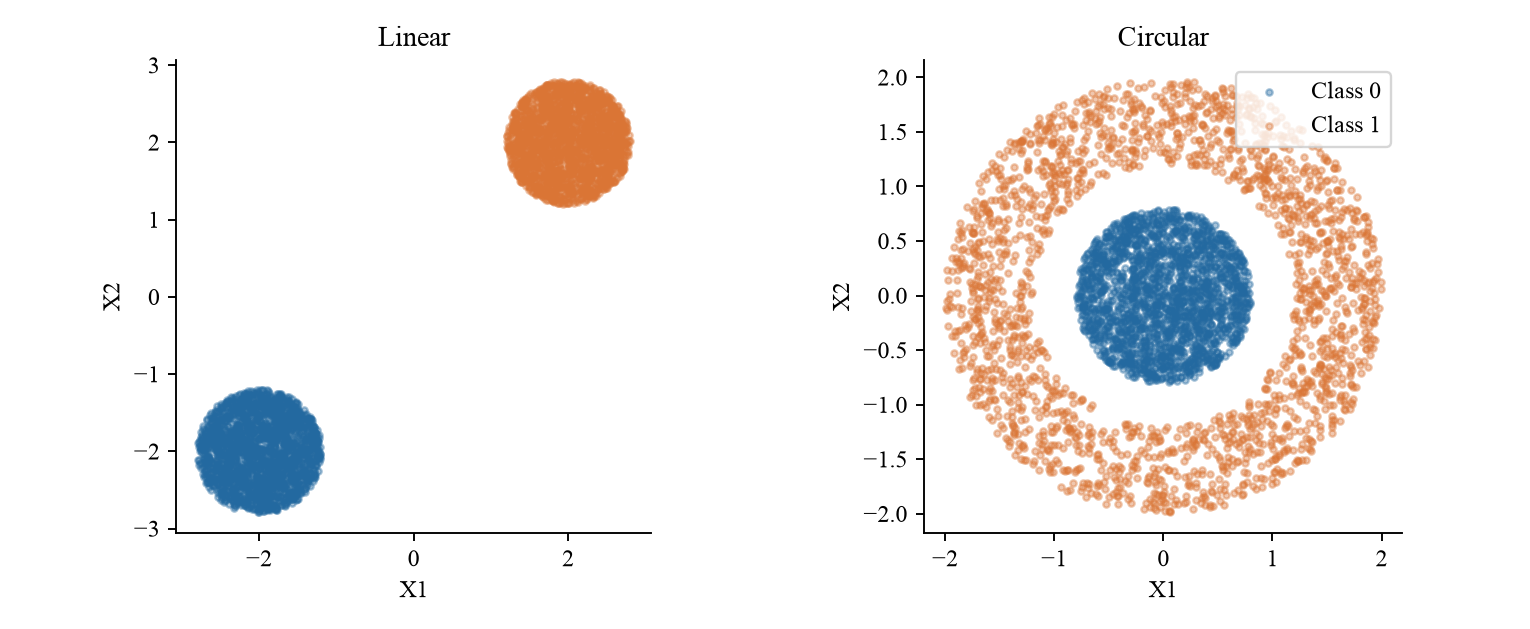

In [3]:
def generate(kind, seed):
    rng = np.random.default_rng(seed)
    y = np.repeat([0, 1], N // 2)
    theta = rng.uniform(0, 2 * np.pi, N)
    if kind == 'linear':
        radius = .8 * np.sqrt(rng.random(N))
        x = np.column_stack((radius * np.cos(theta), radius * np.sin(theta)))
        x += np.where(y[:, None] == 0, [-2., -2.], [2., 2.])
    else:
        # Uniform area sampling: central disk and surrounding annulus.
        radius = np.where(y == 0, .8 * np.sqrt(rng.random(N)),
                          np.sqrt(1.2**2 + (2.**2 - 1.2**2) * rng.random(N)))
        x = np.column_stack((radius * np.cos(theta), radius * np.sin(theta)))
    return x, y

results = {'settings': dict(seed=SEED, n=N, repeats=REPEATS, k=K), 'linear_models': {}, 'kernels': {}}
data, splits, models = {}, {}, {}
for i, kind in enumerate(['linear', 'circular']):
    x, y = generate(kind, SEED + i)
    data[kind] = (x, y)
    splits[kind] = train_test_split(x, y, test_size=.3, stratify=y, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.7))
for ax, (kind, (x, y)) in zip(axes, data.items()): scatter(ax, x, y, kind.capitalize())
axes[1].legend(loc='upper right')
show_figure()


In [4]:
show_table(['Dataset', 'Total', 'Training', 'Test', 'Classes'], [
    [kind, len(data[kind][1]), len(split[2]), len(split[3]), '0 and 1 (balanced)']
    for kind, split in splits.items()
])


| Dataset | Total | Training | Test | Classes |
| --- | --- | --- | --- | --- |
| linear | 4000 | 2800 | 1200 | 0 and 1 (balanced) |
| circular | 4000 | 2800 | 1200 | 0 and 1 (balanced) |

This construction deliberately separates the effect of geometry from measurement noise. Both datasets are separable, but the circular dataset requires a nonlinear boundary.


## 2. Perceptron and linear SVM

Both models predict a class from the sign of w^T x + b. A perceptron updates its weights when an observation is misclassified. A linear SVM balances a wide margin against classification errors. For labels encoded as -1 and +1, its objective is 0.5 ||w||^2 + C sum max(0, 1 - y_i(w^T x_i + b)). The margin is the distance between the boundary and the nearby class observations.

We standardized each feature using the training mean and standard deviation, then applied the same transformation to the test data. We used C = 1 for the linear SVM. The perceptron used a fixed seed, at most 2,000 passes, and tolerance 0.0001. These are fixed baseline settings, not settings selected from the test results.


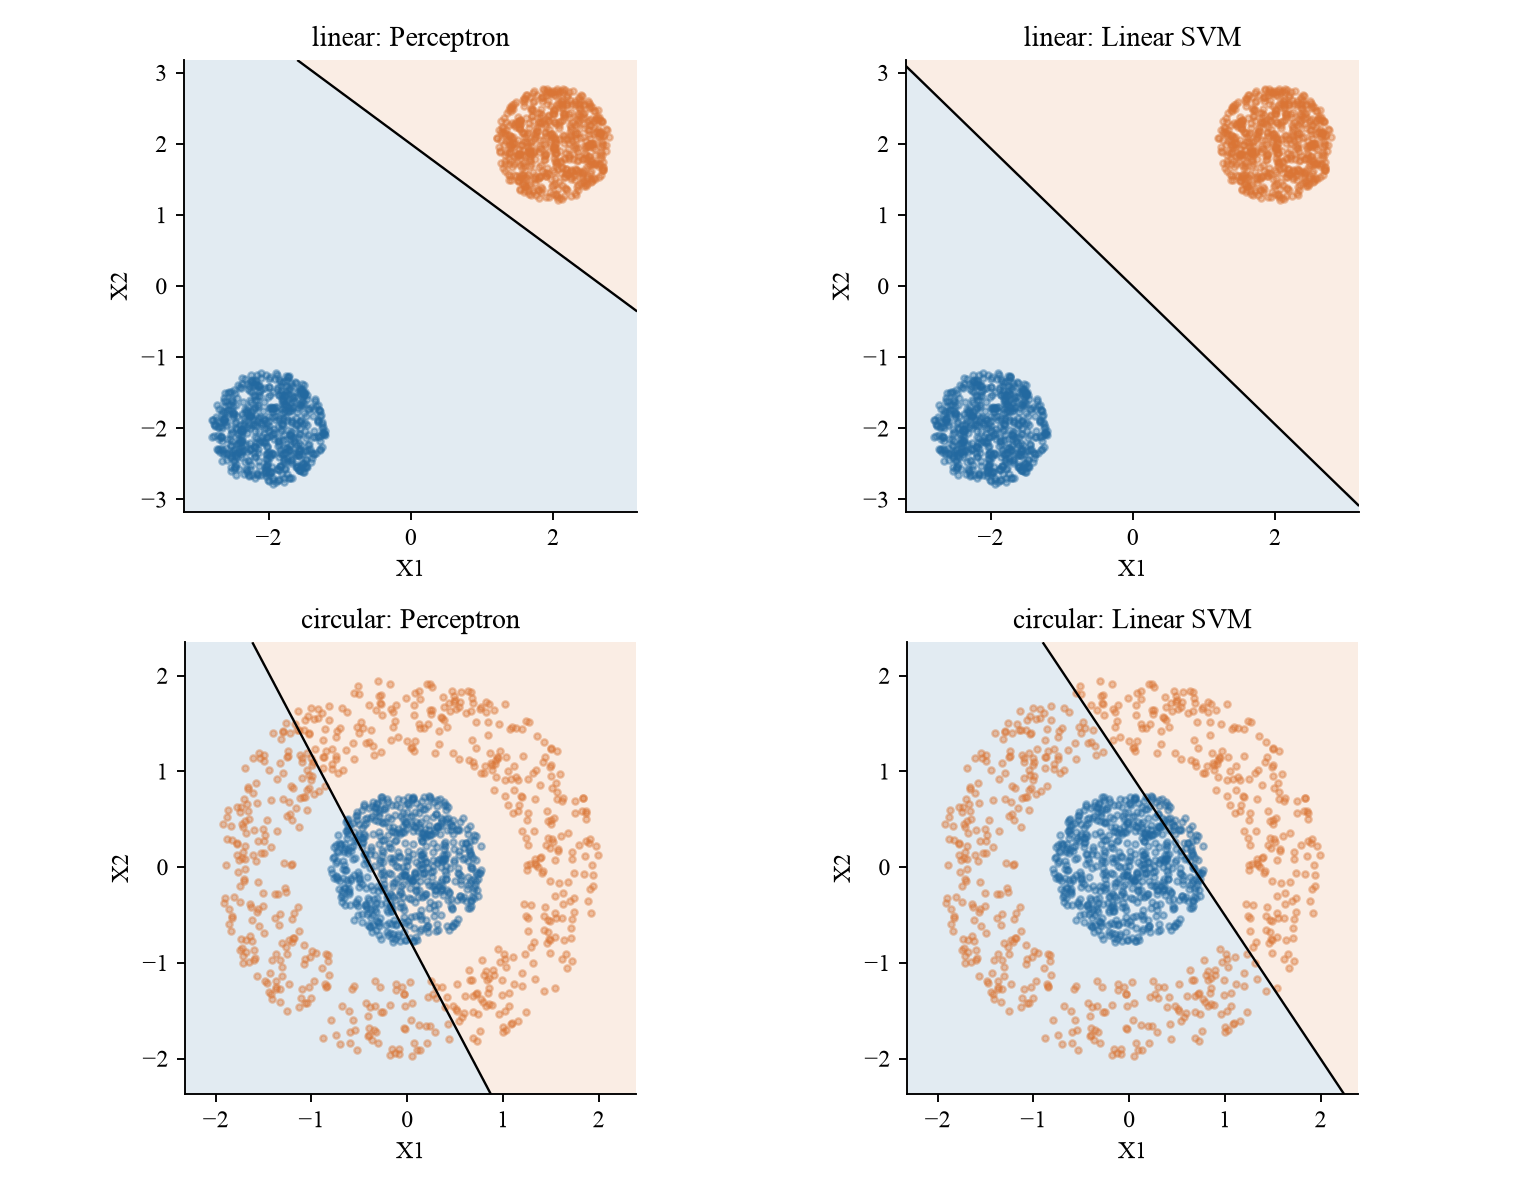

Linear comparisons complete


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(9, 7))
for row, (kind, (X_train, X_test, y_train, y_test)) in enumerate(splits.items()):
    for col, (name, model) in enumerate([
        ('Perceptron', make_pipeline(StandardScaler(), Perceptron(random_state=SEED, max_iter=2000, tol=1e-4))),
        ('Linear SVM', svm('linear', C=1))]):
        model.fit(X_train, y_train)
        results['linear_models'][kind + ' / ' + name] = {'train': metrics(model, X_train, y_train), 'test': metrics(model, X_test, y_test)}
        models[kind + name] = model
        boundary(axes[row, col], model, X_test, y_test, f'{kind}: {name}')
show_figure()
print('Linear comparisons complete', flush=True)


In [6]:
show_table(['Dataset / model', 'Train accuracy', 'Test accuracy', 'Test F1'], [
    [name, percent(value['train']['accuracy']), percent(value['test']['accuracy']),
     f"{value['test']['f1']:.3f}"]
    for name, value in results['linear_models'].items()
])


| Dataset / model | Train accuracy | Test accuracy | Test F1 |
| --- | --- | --- | --- |
| linear / Perceptron | 100.00% | 100.00% | 1.000 |
| linear / Linear SVM | 100.00% | 100.00% | 1.000 |
| circular / Perceptron | 41.32% | 41.50% | 0.497 |
| circular / Linear SVM | 65.50% | 64.75% | 0.527 |

Both linear models achieved 100% test accuracy on the two distant disks. On the circular dataset, the perceptron achieved 41.50% and the linear SVM achieved 64.75%. A straight line can classify part of the ring correctly, but cannot enclose the inner class. Its errors therefore reflect an unsuitable model shape, or underfitting. Increasing the number of training observations would not remove this geometric limitation. The perceptron is not guaranteed to converge to a separating solution on these nonlinearly separable inputs.

Accuracy is the fraction of correct predictions. F1 = 2TP / (2TP + FP + FN) balances precision and recall for class 1. TP means true positives, FP false positives, and FN false negatives. A model can have near-chance accuracy and a nonzero F1, especially when it predicts one class more often.


## 3. Separating the circular data with kernels

A kernel lets an SVM use a nonlinear boundary through similarities between observations. We compared a degree-two polynomial kernel, K(x, z) = (gamma x^T z)^2, with a radial basis function (RBF) kernel, K(x, z) = exp(-gamma ||x - z||^2). The polynomial kernel includes quadratic features, which suit a boundary based on x1^2 + x2^2. The RBF kernel can represent more flexible local boundaries.

For each kernel, we selected C from {0.1, 1, 10} and gamma from {0.1, 0.5, 1} using three-fold stratified cross-validation on the training set. Scaling was fitted separately inside each fold. We chose the highest validation accuracy; if the kernels tied, our rule was to prefer the degree-two polynomial because its structure matches the known radial geometry. We then fitted the selected settings on all training observations.


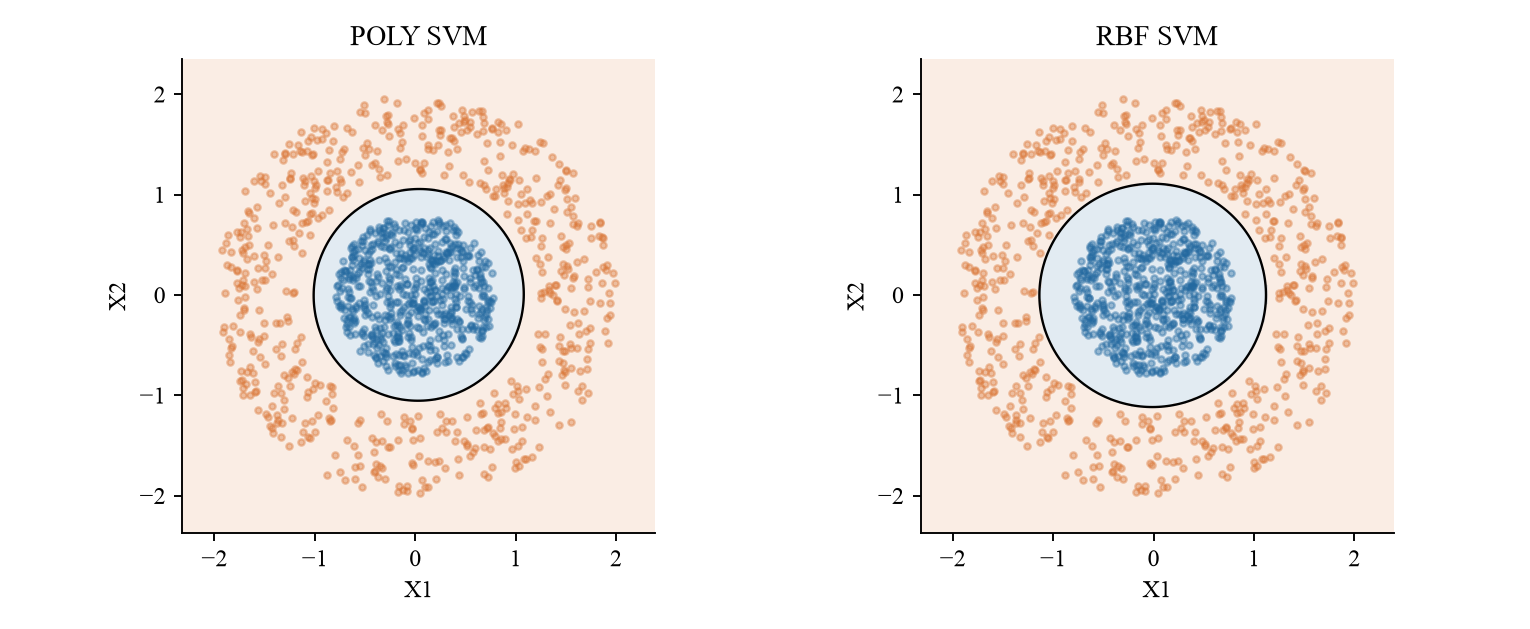

Selected kernel: poly


In [7]:
X_train, X_test, y_train, y_test = splits['circular']
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
for kernel in ['poly', 'rbf']:
    model = svm(kernel, degree=2, coef0=0)
    search = GridSearchCV(model, {'svc__C': [.1, 1, 10], 'svc__gamma': [.1, .5, 1]}, cv=cv, scoring='accuracy', n_jobs=1)
    search.fit(X_train, y_train)
    models[kernel] = search.best_estimator_
    results['kernels'][kernel] = {'cv_accuracy': search.best_score_, 'params': search.best_params_,
        'support_vectors': int(sum(search.best_estimator_[-1].n_support_)),
        'train': metrics(search.best_estimator_, X_train, y_train), 'test': metrics(search.best_estimator_, X_test, y_test)}
# Prespecified tie rule: prefer degree-two polynomial, matching the radial geometry.
best = max(['poly', 'rbf'], key=lambda key: (results['kernels'][key]['cv_accuracy'], key == 'poly'))
results['best_kernel'] = best
best_model = models[best]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.7))
for ax, kernel in zip(axes, ['poly', 'rbf']): boundary(ax, models[kernel], X_test, y_test, kernel.upper() + ' SVM')
show_figure()
print('Selected kernel:', best)


In [8]:
show_table(['Kernel', 'C', 'gamma', 'CV accuracy', 'Test accuracy', 'F1', 'AUC'], [
    [name, value['params']['svc__C'], value['params']['svc__gamma'],
     percent(value['cv_accuracy']), percent(value['test']['accuracy']),
     f"{value['test']['f1']:.3f}", f"{value['test']['auc']:.3f}"]
    for name, value in results['kernels'].items()
])
for name, value in results['kernels'].items():
    display(Markdown(f"**{name.upper()} confusion matrix** (rows: true class; columns: predicted class)"))
    show_table(['', 'Predicted 0', 'Predicted 1'], [
        ['True 0', *value['test']['confusion'][0]],
        ['True 1', *value['test']['confusion'][1]]
    ])
    print(f"Training accuracy: {percent(value['train']['accuracy'])}; support vectors: {value['support_vectors']}")


| Kernel | C | gamma | CV accuracy | Test accuracy | F1 | AUC |
| --- | --- | --- | --- | --- | --- | --- |
| poly | 0.1 | 0.5 | 100.00% | 100.00% | 1.000 | 1.000 |
| rbf | 0.1 | 0.1 | 100.00% | 100.00% | 1.000 | 1.000 |

**POLY confusion matrix** (rows: true class; columns: predicted class)

|  | Predicted 0 | Predicted 1 |
| --- | --- | --- |
| True 0 | 600 | 0 |
| True 1 | 0 | 600 |

Training accuracy: 100.00%; support vectors: 205


**RBF confusion matrix** (rows: true class; columns: predicted class)

|  | Predicted 0 | Predicted 1 |
| --- | --- | --- |
| True 0 | 600 | 0 |
| True 1 | 0 | 600 |

Training accuracy: 100.00%; support vectors: 834


The selected model is the POLY SVM. Both kernels achieved perfect validation and test scores, so neither showed better predictive accuracy in this experiment. Our tie rule is a modeling choice, not evidence of a performance advantage. AUC measures how well the decision scores rank class 1 above class 0 across thresholds; it does not require probability estimates.


## 4. Gaussian augmentation and generalization

We kept the selected circular SVM fixed. For each replicate, we sampled 1,000 observations with replacement from the held-out circular test set, added independent Gaussian noise to both coordinates, and retained the original labels. We repeated this 10,000 times for each noise level, producing 10 million perturbed observations per level. Sampling with replacement allows repeated resampling of the finite test set.

The perturbation is x_aug = x + epsilon, with epsilon distributed as N(0, sigma^2 I). SD means standard deviation; pp in the tables means percentage points. We used low SD = 0.1 and high SD = 0.8 in the original coordinate units. The PDF does not specify numerical SD values. The low level is small relative to the 0.4 radial gap; the high level is twice that gap. We did not retrain on these augmented observations, so this is a robustness test rather than an augmentation-training experiment.


Completed augmentation with SD = 0.1


Completed augmentation with SD = 0.8


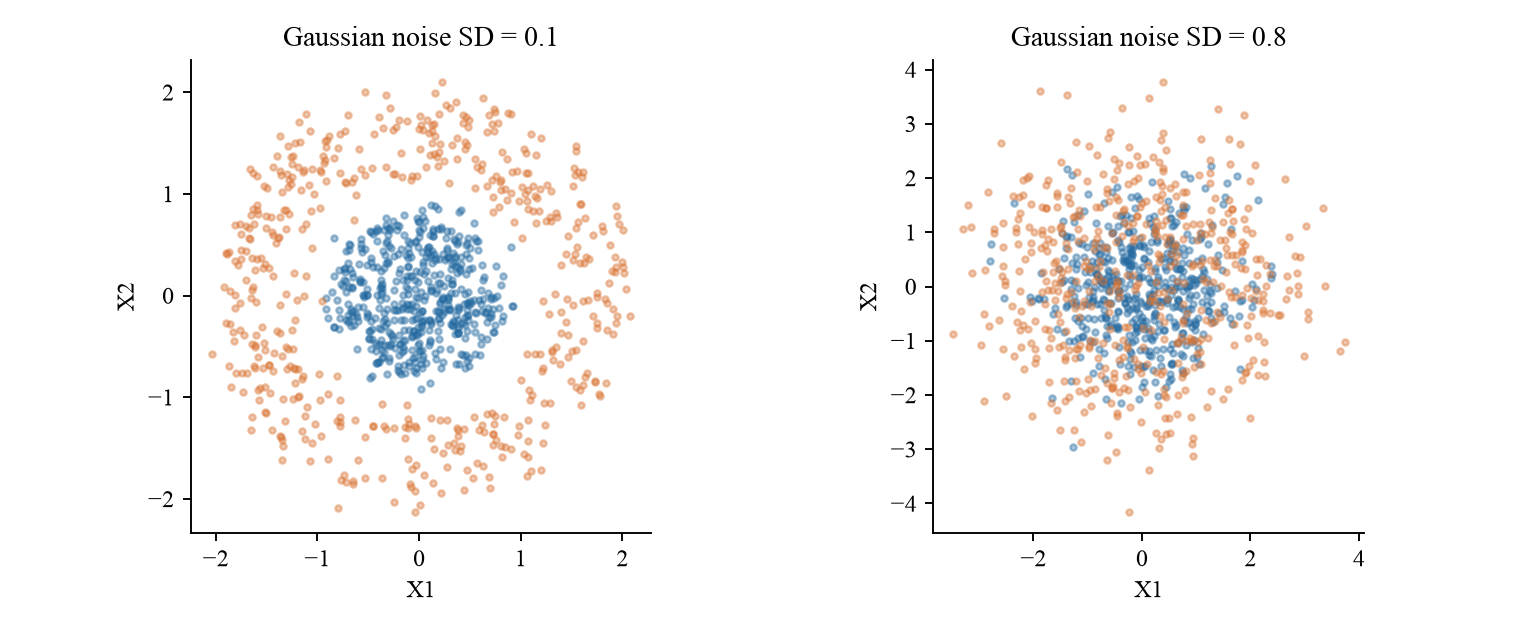

In [9]:
X_train, X_test, y_train, y_test = splits['circular']
# Stress-test a fixed model on held-out observations; never augment training points here.
results['augmentation'] = {}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.7))
for ax, sigma in zip(axes, [.1, .8]):
    rng = np.random.default_rng(100)
    scores = []
    pooled_cm = np.zeros((2, 2), dtype=np.int64)
    for batch in range(K // 100):
        # Process 100 independent replicates at once to keep memory bounded.
        ids = rng.choice(len(y_test), size=(100, 1000), replace=True)
        points = X_test[ids] + rng.normal(0, sigma, (100, 1000, 2))
        pred = best_model.predict(points.reshape(-1, 2)).reshape(100, 1000)
        labels = y_test[ids]
        scores.extend(np.mean(pred == labels, axis=1).tolist())
        np.add.at(pooled_cm, (labels.ravel(), pred.ravel()), 1)
        if batch == 0: scatter(ax, points[0], labels[0], f'Gaussian noise SD = {sigma}')
    tn, fp, fn, tp = pooled_cm.ravel()
    results['augmentation'][str(sigma)] = dict(mean_accuracy=float(np.mean(scores)), sd_accuracy=float(np.std(scores, ddof=1)),
        interval=np.quantile(scores, [.025, .975]).tolist(), f1=float(2*tp/(2*tp+fp+fn)), confusion=pooled_cm.tolist())
    print(f'Completed augmentation with SD = {sigma}')
show_figure()


In [10]:
show_table(['Noise SD', 'Mean accuracy', 'Replicate SD (pp)', 'Central 95% of replicates', 'Pooled F1'], [
    [sigma, percent(value['mean_accuracy']), f"{100 * value['sd_accuracy']:.2f}",
     f"{percent(value['interval'][0])} to {percent(value['interval'][1])}", f"{value['f1']:.3f}"]
    for sigma, value in results['augmentation'].items()
])


| Noise SD | Mean accuracy | Replicate SD (pp) | Central 95% of replicates | Pooled F1 |
| --- | --- | --- | --- | --- |
| 0.1 | 99.84% | 0.13 | 99.50% to 100.00% | 0.998 |
| 0.8 | 67.12% | 1.48 | 64.20% to 70.00% | 0.721 |

Low noise mostly preserves the original geometry. High noise moves more observations across the learned boundary, so their retained labels become harder to infer from their new positions. This explains the accuracy loss without requiring the model to have memorized its training data.

The clean training and test results provide no evidence of a large overfitting gap on this easy simulation. However, success on clean data does not guarantee robustness to a different input distribution. The intervals above describe variation among noisy 1,000-point replicates; they are not confidence intervals over independently generated datasets. Reusing test observations does not create 10 million independent original observations.


## 5. Incorrect training labels

We returned to the original, unaugmented datasets. We selected 0%, 15%, 25%, or 50% of the training indices and randomly permuted labels within that subset. We refitted the linear SVM for the linear dataset and the selected kernel SVM for the circular dataset, keeping their settings fixed. Test inputs and labels were unchanged. Each nonzero corruption level was repeated with five seeds; the zero-noise baseline is deterministic.

Selecting a label for shuffling does not guarantee that it changes. With balanced binary classes, a selected label has approximately a 50% chance of retaining its value. Therefore, shuffling 50% of training labels changes roughly 25% of all training labels, rather than 50%. We report the observed changed fraction to make this distinction explicit.


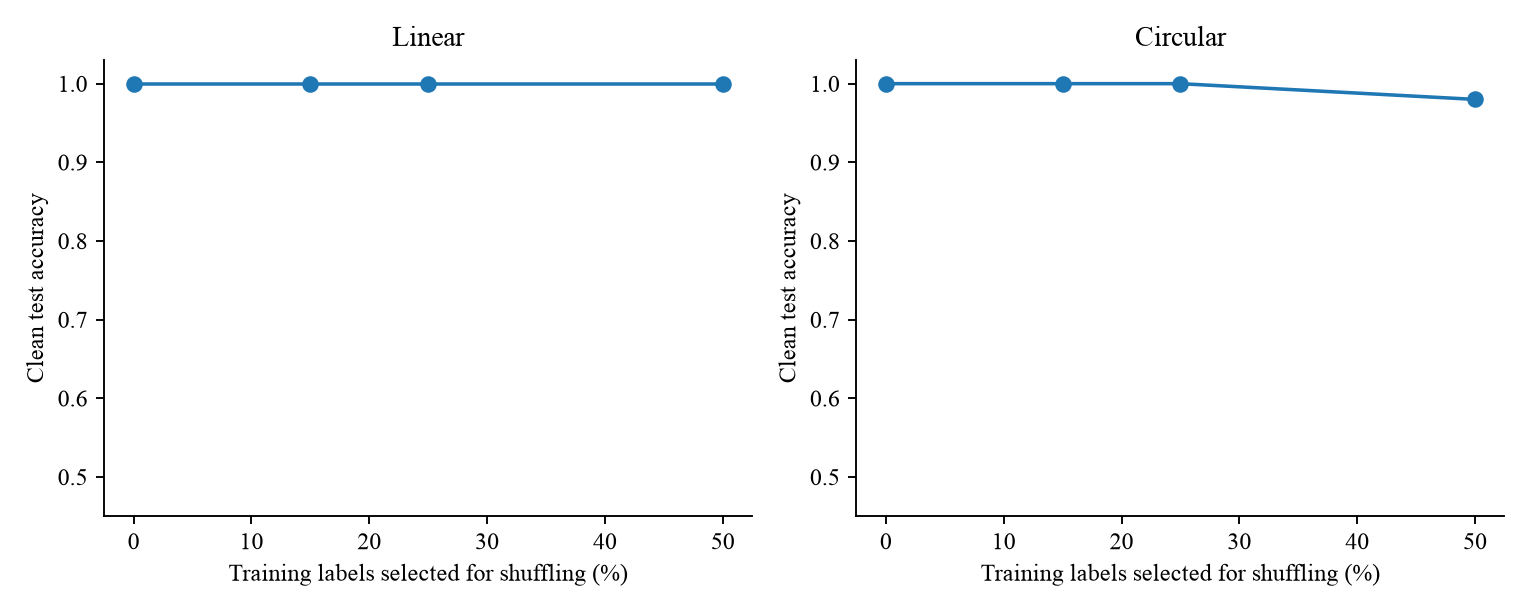

Label noise complete


In [11]:
def shuffle_labels(y, fraction, seed):
    rng = np.random.default_rng(seed)
    indices = rng.choice(len(y), round(fraction * len(y)), replace=False)
    noisy = y.copy()
    noisy[indices] = rng.permutation(noisy[indices])
    return noisy, float(np.mean(noisy != y))

results['noise'] = {}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, kind in zip(axes, ['linear', 'circular']):
    X_train, X_test, y_train, y_test = splits[kind]
    rows = []
    for fraction in [0, .15, .25, .5]:
        trials = []
        for repeat in range(REPEATS):
            noisy, changed = shuffle_labels(y_train, fraction, 200 + repeat)
            model = svm('linear', C=1) if kind == 'linear' else svm(best, degree=2, coef0=0, **{k.split('__')[1]: v for k,v in results['kernels'][best]['params'].items()})
            model.fit(X_train, noisy)
            trials.append(dict(changed=changed, train_noisy=accuracy_score(noisy, model.predict(X_train)), **metrics(model, X_test, y_test)))
        rows.append(dict(fraction=fraction, trials=trials))
    results['noise'][kind] = rows
    ax.errorbar([100*r['fraction'] for r in rows], [np.mean([t['accuracy'] for t in r['trials']]) for r in rows],
                yerr=[np.std([t['accuracy'] for t in r['trials']], ddof=1) for r in rows], marker='o', capsize=3)
    ax.set(title=kind.capitalize(), xlabel='Training labels selected for shuffling (%)', ylabel='Clean test accuracy', ylim=(.45, 1.03))
show_figure()
print('Label noise complete', flush=True)


In [12]:
noise_rows = []
for kind, conditions in results['noise'].items():
    for condition in conditions:
        trials = condition['trials']
        accuracies = [trial['accuracy'] for trial in trials]
        noise_rows.append([
            kind, percent(condition['fraction']),
            percent(np.mean([trial['changed'] for trial in trials])),
            percent(np.mean([trial['train_noisy'] for trial in trials])),
            percent(np.mean(accuracies)), f"{100 * np.std(accuracies, ddof=1):.2f}"
        ])
show_table(['Dataset', 'Selected', 'Actually changed', 'Fit to noisy labels', 'Clean test accuracy', 'SD (pp)'], noise_rows)


| Dataset | Selected | Actually changed | Fit to noisy labels | Clean test accuracy | SD (pp) |
| --- | --- | --- | --- | --- | --- |
| linear | 0.00% | 0.00% | 100.00% | 100.00% | 0.00 |
| linear | 15.00% | 7.67% | 92.33% | 100.00% | 0.00 |
| linear | 25.00% | 12.60% | 87.40% | 100.00% | 0.00 |
| linear | 50.00% | 25.37% | 74.63% | 100.00% | 0.00 |
| circular | 0.00% | 0.00% | 100.00% | 100.00% | 0.00 |
| circular | 15.00% | 7.67% | 92.33% | 100.00% | 0.00 |
| circular | 25.00% | 12.60% | 87.38% | 100.00% | 0.00 |
| circular | 50.00% | 25.37% | 73.69% | 98.00% | 0.31 |

The linear SVM retained 100% clean test accuracy at all tested levels. The circular SVM also retained 100% through 25% selected labels, then decreased to 98.00% on average at 50%. The underlying class geometry is strong, and the labels remain mostly correct even at the highest selected fraction. A model can therefore retain high clean test accuracy while disagreeing with many corrupted training labels. Lower agreement with noisy training labels is not necessarily worse generalization.

These results do not imply that label errors are harmless in general. The datasets are balanced and have a clear class gap, and the permutation preserves training class counts. Targeted mistakes near the boundary, weaker class separation, or a higher actual corruption rate could have a larger effect. Five permutations measure only a limited part of the uncertainty.


## 6. Higher-dimensional inputs

We created 5-, 10-, and 15-dimensional versions of both original datasets, retaining the two original informative coordinates and adding independent N(0, 1) features that contain no label information. We also retained the 2D baseline. The features are nested: the extra coordinates used in 5D are also present in 10D and 15D. We used the same observations, split, corruption levels, and five label-permutation seeds as before.

This design isolates the effect of irrelevant dimensions. It does not test a different problem in which every new coordinate carries useful information. Each model standardizes all features using training data only. We kept the 2D SVM hyperparameters fixed to measure sensitivity of the existing model; dimension-specific retuning might improve performance.


Dimensions complete linear 2


Dimensions complete linear 5


Dimensions complete linear 10


Dimensions complete linear 15


Dimensions complete circular 2


Dimensions complete circular 5


Dimensions complete circular 10


Dimensions complete circular 15


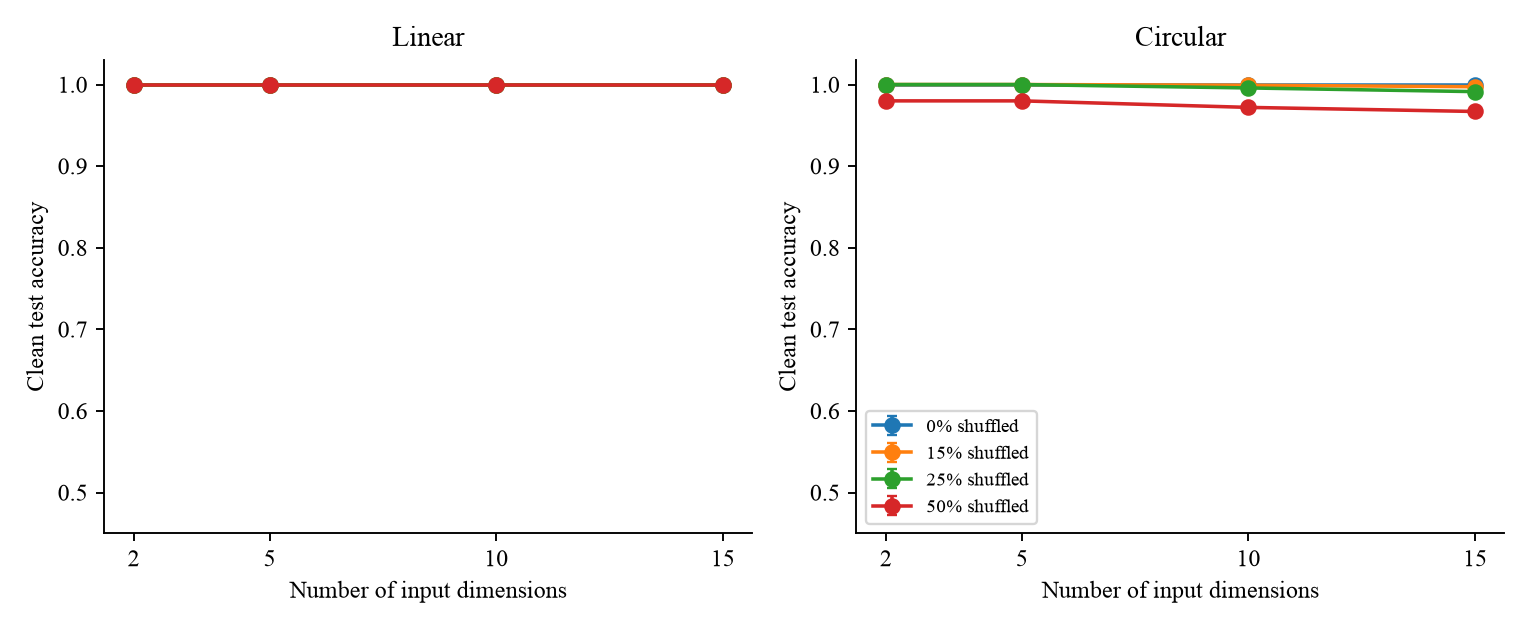

In [13]:
results['dimensions'] = {}
fig, axes = plt.subplots(1, 2, figsize=(9, 3.7))
for ax, kind in zip(axes, ['linear', 'circular']):
    x, y = data[kind]
    # Nested irrelevant features: 5D is a subset of 10D and 15D.
    extra = np.random.default_rng(300).normal(size=(N, 13))
    rows = []
    for dim in [2, 5, 10, 15]:
        expanded = np.column_stack([x, extra[:, :dim-2]])
        X_train, X_test, y_train, y_test = train_test_split(expanded, y, test_size=.3, stratify=y, random_state=SEED)
        for fraction in [0, .15, .25, .5]:
            scores = []
            for repeat in range(REPEATS):
                noisy, _ = shuffle_labels(y_train, fraction, 200 + repeat)
                model = svm('linear', C=1) if kind == 'linear' else svm(best, degree=2, coef0=0, **{k.split('__')[1]:v for k,v in results['kernels'][best]['params'].items()})
                model.fit(X_train, noisy)
                scores.append(accuracy_score(y_test, model.predict(X_test)))
            rows.append(dict(dim=dim, fraction=fraction, scores=scores))
        print('Dimensions complete', kind, dim, flush=True)
    results['dimensions'][kind] = rows
    for fraction in [0, .15, .25, .5]:
        subset = [r for r in rows if r['fraction'] == fraction]
        ax.errorbar([r['dim'] for r in subset], [np.mean(r['scores']) for r in subset],
                    yerr=[np.std(r['scores'], ddof=1) for r in subset], marker='o', capsize=2, label=f'{100*fraction:g}% shuffled')
    ax.set(title=kind.capitalize(), xlabel='Number of input dimensions', ylabel='Clean test accuracy', xticks=[2,5,10,15], ylim=(.45, 1.03))
axes[1].legend(fontsize=8)
show_figure()


In [14]:
dimension_rows = []
for kind, conditions in results['dimensions'].items():
    for dimension in [2, 5, 10, 15]:
        scores = [next(row['scores'] for row in conditions
                       if row['dim'] == dimension and row['fraction'] == fraction)
                  for fraction in [0, .15, .25, .5]]
        dimension_rows.append([kind, dimension] + [percent(np.mean(values)) for values in scores])
show_table(['Dataset', 'Dimensions', '0% shuffled', '15% shuffled', '25% shuffled', '50% shuffled'], dimension_rows)


| Dataset | Dimensions | 0% shuffled | 15% shuffled | 25% shuffled | 50% shuffled |
| --- | --- | --- | --- | --- | --- |
| linear | 2 | 100.00% | 100.00% | 100.00% | 100.00% |
| linear | 5 | 100.00% | 100.00% | 100.00% | 100.00% |
| linear | 10 | 100.00% | 100.00% | 100.00% | 100.00% |
| linear | 15 | 100.00% | 100.00% | 100.00% | 100.00% |
| circular | 2 | 100.00% | 100.00% | 100.00% | 98.00% |
| circular | 5 | 100.00% | 100.00% | 100.00% | 98.00% |
| circular | 10 | 100.00% | 99.92% | 99.58% | 97.20% |
| circular | 15 | 100.00% | 99.73% | 99.13% | 96.70% |

The linear dataset remained at 100% accuracy across all conditions. For the circular dataset with 50% selected labels, mean accuracy decreased from 98.00% in 2D to 96.70% in 15D; without label corruption, it remained 100%. Extra features give the model more ways to fit accidental patterns. For a degree-two polynomial kernel, the number of quadratic feature terms is d(d + 1)/2: it grows from 3 at d = 2 to 120 at d = 15. These extra terms may interact with incorrect labels even though they add no useful class information. A linear model can more easily ignore irrelevant coordinates when the original separation is large.

Accuracy did not decrease at every step. The observed curves depend on the separation, sample size, regularization, and particular noise draws. Any small changes here are conditional on one generated pair of datasets; repeated independent dataset generation would be needed for a broader claim.


## Bonus: a 70% performance threshold

To make the threshold question precise, we increased the strength of each augmentation using effective SD = t times the base SD, where t = 0, 1, ..., 20. The base SDs are 0.1 and 0.8. At each point, we evaluated the same fixed circular SVM on 200 resamples of 1,000 test observations. We reused the random draws across settings to make comparisons less affected by simulation variation. The full 10,000 replicates were used for Section 4; this additional threshold sweep uses 200 per setting.


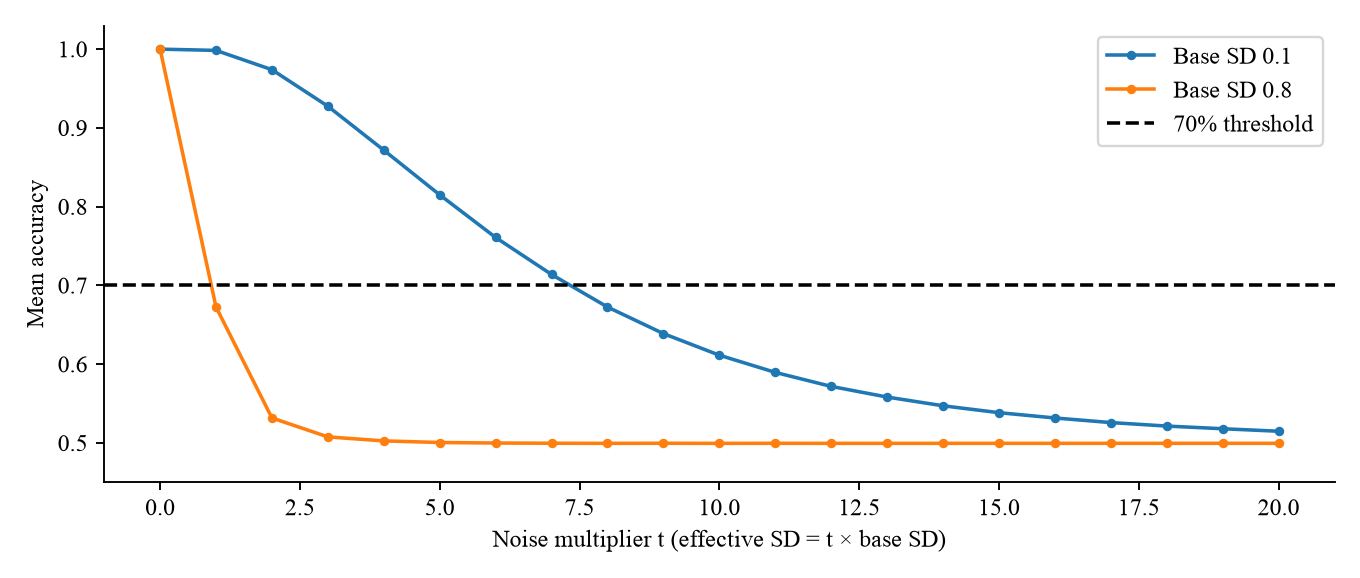

In [15]:
# Bonus: progressively increase the SD of both specified augmentation regimes.
X_train, X_test, y_train, y_test = splits['circular']
results['bonus'] = []
for multiplier in np.arange(0, 21, 1):
    for base_sigma in [.1, .8]:
        rng = np.random.default_rng(400)
        ids = rng.choice(len(y_test), size=(200, 1000), replace=True)
        points = X_test[ids] + rng.normal(size=(200,1000,2)) * base_sigma * multiplier
        pred = best_model.predict(points.reshape(-1,2)).reshape(200,1000)
        values = np.mean(pred == y_test[ids], axis=1)
        results['bonus'].append(dict(multiplier=int(multiplier), base_sd=base_sigma, sd=float(multiplier*base_sigma), accuracy=float(np.mean(values))))
fig, ax = plt.subplots(figsize=(8, 3.4))
for sigma in [.1,.8]:
    subset = [r for r in results['bonus'] if r['base_sd'] == sigma]
    ax.plot([r['multiplier'] for r in subset], [r['accuracy'] for r in subset], marker='.', label=f'Base SD {sigma}')
ax.axhline(.7, linestyle='--', color='black', label='70% threshold')
ax.set(xlabel='Noise multiplier t (effective SD = t × base SD)', ylabel='Mean accuracy', ylim=(.45,1.03))
ax.legend()
show_figure()


In [16]:
threshold_rows = []
for base_sd in [.1, .8]:
    conditions = [row for row in results['bonus'] if row['base_sd'] == base_sd]
    crossing = next((row for row in conditions if row['accuracy'] < .7), None)
    if crossing is None:
        threshold_rows.append([base_sd, 'Not reached', '-', '-', '-'])
    else:
        previous = conditions[conditions.index(crossing) - 1]
        threshold_rows.append([base_sd, crossing['multiplier'], f"{crossing['sd']:.2f}",
                               percent(crossing['accuracy']),
                               f"({previous['sd']:.2f}, {crossing['sd']:.2f}]"])
show_table(['Base SD', 'First multiplier below 70%', 'Effective SD', 'Accuracy', 'SD bracket'], threshold_rows)


| Base SD | First multiplier below 70% | Effective SD | Accuracy | SD bracket |
| --- | --- | --- | --- | --- |
| 0.1 | 8 | 0.80 | 67.26% | (0.70, 0.80] |
| 0.8 | 1 | 0.80 | 67.26% | (0.00, 0.80] |

The reported crossing is the first sampled point below 70%, not an exact threshold. A finer grid would locate it more precisely. Both curves describe the same Gaussian perturbation mechanism at different scales, so their multiplier thresholds should differ. Their effective-SD brackets are the more meaningful comparison. Increasing the number of replicates alone would not systematically reduce expected accuracy; increasing the noise strength changes the task.

This is a robustness threshold, not proof of overfitting. At high noise, the class distributions overlap strongly while the original labels stay fixed. Even a suitable clean-data classifier can then perform poorly.


## Checks

We checked that each augmentation level contained 10 million observations and that the 2D results agreed between Questions 5 and 6.

In [17]:
for value in results['augmentation'].values():
    assert sum(map(sum, value['confusion'])) == K * 1000

for kind, conditions in results['dimensions'].items():
    for condition in conditions:
        if condition['dim'] == 2:
            baseline = next(row for row in results['noise'][kind]
                            if row['fraction'] == condition['fraction'])
            np.testing.assert_allclose(condition['scores'],
                                       [trial['accuracy'] for trial in baseline['trials']])

print('The augmentation counts and 2D baselines are consistent.')


The augmentation counts and 2D baselines are consistent.
